#1. Import Data

In [ ]:
# generic setup cell we can re-use for all notebooks
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
import sys
import random
import numpy as np
import pandas as pd
ROOT = '/content/drive/MyDrive/Google_Colab_Share_Folder/MLSN_F26_Group_2_(CRISPR)'
DATA = os.path.join(ROOT, 'data', 'processed')
MODELS = os.path.join(ROOT, 'models')
sys.path.append(os.path.join(ROOT, 'src'))


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print(os.path.exists(ROOT))  # should print True

Mounted at /content/drive
True


In [ ]:
import re
import pickle

In [ ]:
dataset = pd.read_csv(os.path.join(DATA, 'deephf_cleaned_all_59852.csv'))
dataset.head()

,gRNA_ID,gRNA_Seq,PAM,21mer,WT_Efficiency,eSpCas9_Efficiency,SpCas9_HF1_Efficiency
0,GRNA-1,AAAAAAAAACTCCAAAACCC,TGG,AAAAAAAAACTCCAAAACCCT,0.168570,0.142063,0.093147
1,GRNA-2,AAAAAACAACAAGAAGCACA,AGG,AAAAAACAACAAGAAGCACAA,0.099624,0.051901,0.064951
2,GRNA-3,AAAAAACACAAGCAAGACCG,TGG,AAAAAACACAAGCAAGACCGT,0.247750,0.043573,0.061797
3,GRNA-4,AAAAAACAGATGCCACCTGT,GGG,AAAAAACAGATGCCACCTGTG,0.141232,0.052343,0.057246
4,GRNA-5,AAAAAACCCGTAGATAGCCT,CGG,AAAAAACCCGTAGATAGCCTC,0.045803,0.046234,0.067596


In [ ]:
dataset = dataset[['WT_Efficiency','gRNA_Seq']].dropna().reset_index(drop=True)
dataset.head()

,WT_Efficiency,gRNA_Seq
0,0.168570,AAAAAAAAACTCCAAAACCC
1,0.099624,AAAAAACAACAAGAAGCACA
2,0.247750,AAAAAACACAAGCAAGACCG
3,0.141232,AAAAAACAGATGCCACCTGT
4,0.045803,AAAAAACCCGTAGATAGCCT


In [ ]:
dataset.shape

(55604, 2)

# 2. 76.5% Training, 8.5% Validation, 15% Test Splits

In [ ]:
from sklearn.model_selection import train_test_split

def create_deephf_splits(dataframe, target_col, seed=SEED):
    """
    Filters out NaNs for WT_Efficiency and splits into:
      - 76.5% Train
      - 8.5%  Validation
      - 15.0% Test
    """

    # Step 1: Hold out 15% for Test
    train_val_df, test_df = train_test_split(
        dataframe,
        test_size=0.15,
        random_state=seed
    )

    # Step 2: Hold out 10% of remaining 85% for Validation
    train_df, val_df = train_test_split(
        train_val_df,
        test_size=0.10,
        random_state=seed
    )

    return (
        train_df.reset_index(drop=True),
        val_df.reset_index(drop=True),
        test_df.reset_index(drop=True)
    )

# Generate and verify splits
splits = {}

tr, va, te = create_deephf_splits(
    dataset,
    'WT_Efficiency'
)

splits[1] = {
    'train': tr,
    'val': va,
    'test': te
}

print(
    f"WT_Efficiency | Total: {len(tr)+len(va)+len(te):>6,} | "
    f"Train (76.5%): {len(tr):>6,} | "
    f"Val (8.5%): {len(va):>5,} | "
    f"Test (15%): {len(te):>5,}"
)

WT_Efficiency | Total: 55,604 | Train (76.5%): 42,536 | Val (8.5%): 4,727 | Test (15%): 8,341


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    dataset['gRNA_Seq'],
    dataset['WT_Efficiency'],
    test_size=0.15,
    random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=SEED
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(42536,)
(4727,)
(8341,)


# 3. Tokenize and pad gRNA Sequences
* Encoding the four nucleotides 'A', 'C', 'G', and 'T' as 1, 2, 3, and 4 respectively
* Then ensuring all lengths are 20-mer RNA sequences

In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Map characters to integers
char_to_int = {'A': 1, 'C': 2, 'G': 3, 'T': 4}

def tokenize_sequence(seq):
    return [char_to_int.get(char, 0) for char in seq]

# Vectorize the split datasets
X_train_tokenized = [tokenize_sequence(seq) for seq in X_train]
X_val_tokenized = [tokenize_sequence(seq) for seq in X_val]
X_test_tokenized = [tokenize_sequence(seq) for seq in X_test]

# Pad the sequences to a maximum length of 20
max_sequence_length = 20
X_train_padded = pad_sequences(X_train_tokenized, maxlen=max_sequence_length, padding='post')
X_val_padded = pad_sequences(X_val_tokenized, maxlen=max_sequence_length, padding='post')
X_test_padded = pad_sequences(X_test_tokenized, maxlen=max_sequence_length, padding='post')

print("Original sequence sample:", X_train.iloc[0])
print("Tokenized & Padded representation:", X_train_padded[0])

Original sequence sample: AGTGGGCAAAGGCTTCCCAT
Tokenized & Padded representation: [1 3 4 3 3 3 2 1 1 1 3 3 2 4 4 2 2 2 1 4]


# 4. Initial BiLSTM Model with Tensorflow and Keras:
* Base LSTM Model: https://machinecurve.com/index.php/2021/01/07/build-an-lstm-model-with-tensorflow-and-keras
* BiLSTM Layer: https://medium.com/@maheshzen/a-simple-guide-to-bidirectional-lstm-with-keras-implementation-417799a26623

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Embedding, Dense, LSTM, Bidirectional
from tensorflow.keras.losses import MSE, MeanSquaredError
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# Set seeds for Python, NumPy, and TensorFlow
tf.keras.utils.set_random_seed(SEED)

# Enable deterministic TensorFlow operations
tf.config.experimental.enable_op_determinism()

In [ ]:
# Define a learning rate schedule
learning_rate_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.001,
    decay_steps=10000,
    decay_rate=0.96
)

# Create an optimizer with the learning rate schedule
optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate_schedule)

# Model Configuration
additional_metrics = ['R2Score', 'mse', 'mae']
batch_size = 256.
embedding_output_dims = 64
loss_function = MeanSquaredError()
max_sequence_length = 20
num_distinct_words = 16
number_of_epochs = 10
validation_split = 0.20 #keras takes another 20% from training data for validation -> not use it for model.fit
verbosity_mode = 1

In [ ]:
# Build model
model = Sequential()
model.add(Embedding(input_dim=num_distinct_words, output_dim=embedding_output_dims, input_length=max_sequence_length))
model.add(Bidirectional(LSTM(64), merge_mode='sum'))
model.add(Dense(16, activation='elu'))
model.add(Dense(16, activation='elu'))
model.add(Dense(1, activation='linear'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
# Compile the model
model.compile(optimizer=optimizer, loss=loss_function, metrics=additional_metrics)

# Give a summary
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the model
model.fit(X_train_padded, y_train, batch_size=int(batch_size), epochs=number_of_epochs, verbose=verbosity_mode, validation_data = (X_val_padded, y_val))

# Test the model after training
test_results = model.evaluate(X_test_padded, y_test, verbose=False)
print(f'Test results - R2Score: {test_results[1]:.4f} - Loss (MSE): {test_results[0]:.4f} - MAE: {test_results[3]:.4f}')

Epoch 1/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 22s 97ms/step - R2Score: 0.1316 - loss: 0.0412 - mae: 0.1529 - mse: 0.0412 - val_R2Score: 0.3882 - val_loss: 0.0287 - val_mae: 0.1320 - val_mse: 0.0287
Epoch 2/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 20s 95ms/step - R2Score: 0.4171 - loss: 0.0276 - mae: 0.1257 - mse: 0.0276 - val_R2Score: 0.4740 - val_loss: 0.0247 - val_mae: 0.1234 - val_mse: 0.0247
Epoch 3/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 16s 96ms/step - R2Score: 0.4798 - loss: 0.0247 - mae: 0.1172 - mse: 0.0247 - val_R2Score: 0.5309 - val_loss: 0.0220 - val_mae: 0.1115 - val_mse: 0.0220
Epoch 4/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 20s 97ms/step - R2Score: 0.5309 - loss: 0.0222 - mae: 0.1106 - mse: 0.0222 - val_R2Score: 0.5806 - val_loss: 0.0197 - val_mae: 0.1054 - val_mse: 0.0197
Epoch 5/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 16s 96ms/step - R2Score: 0.5748 - loss: 0.0202 - mae: 0.1051 - mse: 0.0202 - val_R2Score: 0.6265 - val_loss: 0.0175 - val_mae: 0.0992 - val_mse: 0.0175
Epoch 6/10
167/167 ━━━━━━━━━━━━━━━━━━━━ 

261/261 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


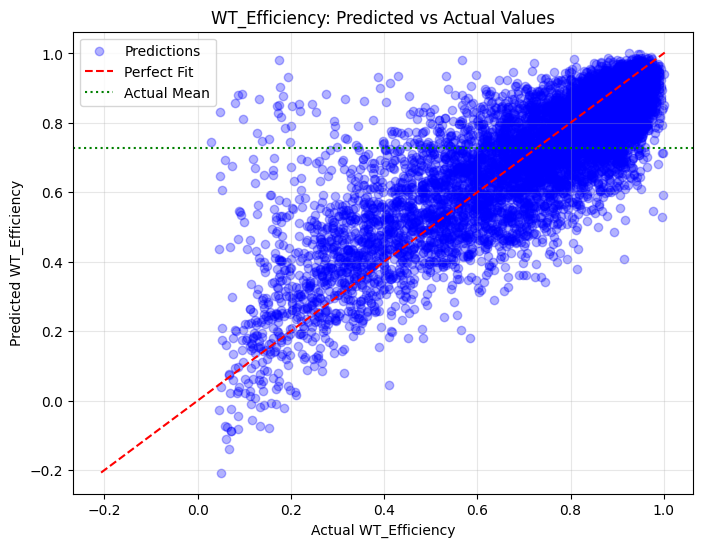

Actual Mean: 0.7271 | Actual Std Dev: 0.2176
Predicted Mean: 0.7189 | Predicted Std Dev: 0.1912
Test results - R2Score: 0.6772 - Loss (MSE): 0.0153 - MAE: 0.0891


In [ ]:
import matplotlib.pyplot as plt

# 1. Generate predictions on the test set using correct tokenized/padded data
y_pred = model.predict(X_test_padded).flatten()

# 2. Plot Predicted vs Actual Values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Predictions')

# Plot the ideal perfect prediction line (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Fit')

# Plot the average line of the actual dataset
plt.axhline(y_test.mean(), color='green', linestyle=':', label='Actual Mean')

plt.title('WT_Efficiency: Predicted vs Actual Values')
plt.xlabel('Actual WT_Efficiency')
plt.ylabel('Predicted WT_Efficiency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print summary statistics to numerical compare spread
print(f"Actual Mean: {y_test.mean():.4f} | Actual Std Dev: {y_test.std():.4f}")
print(f"Predicted Mean: {y_pred.mean():.4f} | Predicted Std Dev: {y_pred.std():.4f}")
print(f'Test results - R2Score: {test_results[1]:.4f} - Loss (MSE): {test_results[0]:.4f} - MAE: {test_results[3]:.4f}')

# 5. Conclusion:
* The model gives an R^2 of about 0.6772. We could try optimizing the hyperparameters using scikit-optimize, adding more layers, or adding positional encodings (which was why we chose the BiLSTM model I think).
* I tried to create sinusoidal positional embeddings (it's in a labeled file version under revision history) but adding them to the tokenized vectors actually ended up making the model worse.

# 6. Grid Search

In [ ]:
from itertools import product
from tensorflow.keras.callbacks import EarlyStopping

def build_model(embedding_dim, lstm_units, learning_rate):

    model = Sequential([
        Embedding(input_dim=5, output_dim=embedding_dim),
        Bidirectional(LSTM(lstm_units), merge_mode='sum'),
        Dense(16, activation='elu'),
        Dense(16, activation='elu'),
        Dense(1, activation='linear')
    ])

    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae', 'R2Score']
    )

    return model

In [ ]:
from itertools import product

param_grid = {
    'learning_rate': [0.0005, 0.001],
    'batch_size': [64, 128, 256],
    'epochs': [10, 15, 20]
}

combinations = list(product(*param_grid.values()))

print("Total combinations:", len(combinations))

Total combinations: 18


In [ ]:
results = []

best_val_r2 = float('-inf')
best_params = None

# Fixed model architecture
fixed_embedding_dim = 64
fixed_lstm_units = 128

for i, (lr, batch_size, epochs) in enumerate(combinations):

    print(f"\nCombination {i+1}/{len(combinations)}")
    print(f"Learning Rate: {lr}, Batch Size: {batch_size}, Epochs: {epochs}")

    # Clear previous model
    tf.keras.backend.clear_session()

    # Reset random seed before building each model
    tf.keras.utils.set_random_seed(SEED)

    # Build model
    model = build_model(
        fixed_embedding_dim,
        fixed_lstm_units,
        lr
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    # Train model
    history = model.fit(
        X_train_padded,
        y_train,
        validation_data=(X_val_padded, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )

    # Evaluate on validation set
    val_mse, val_mae, val_r2 = model.evaluate(
        X_val_padded,
        y_val,
        verbose=0
    )

    # Save results
    results.append({
        'learning_rate': lr,
        'batch_size': batch_size,
        'epochs': epochs,
        'val_r2': val_r2,
        'val_mse': val_mse,
        'val_mae': val_mae
    })

    print(
        f"R²: {val_r2:.4f} | "
        f"MSE: {val_mse:.4f} | "
        f"MAE: {val_mae:.4f}"
    )

    # Update best parameters
    if val_r2 > best_val_r2:

        best_val_r2 = val_r2

        best_params = {
            'embedding_dim': fixed_embedding_dim,
            'lstm_units': fixed_lstm_units,
            'learning_rate': lr,
            'batch_size': batch_size,
            'epochs': epochs
        }

print("\nGrid Search Complete!")
print("Best Parameters:", best_params)
print(f"Best Validation R²: {best_val_r2:.4f}")


Combination 1/18
Learning Rate: 0.0005, Batch Size: 64, Epochs: 10
R²: 0.7271 | MSE: 0.0128 | MAE: 0.0814

Combination 2/18
Learning Rate: 0.0005, Batch Size: 64, Epochs: 15
R²: 0.7380 | MSE: 0.0123 | MAE: 0.0797

Combination 3/18
Learning Rate: 0.0005, Batch Size: 64, Epochs: 20
R²: 0.7380 | MSE: 0.0123 | MAE: 0.0797

Combination 4/18
Learning Rate: 0.0005, Batch Size: 128, Epochs: 10
R²: 0.7070 | MSE: 0.0137 | MAE: 0.0838

Combination 5/18
Learning Rate: 0.0005, Batch Size: 128, Epochs: 15
R²: 0.7305 | MSE: 0.0126 | MAE: 0.0799

Combination 6/18
Learning Rate: 0.0005, Batch Size: 128, Epochs: 20
R²: 0.7391 | MSE: 0.0122 | MAE: 0.0786

Combination 7/18
Learning Rate: 0.0005, Batch Size: 256, Epochs: 10
R²: 0.6824 | MSE: 0.0149 | MAE: 0.0889

Combination 8/18
Learning Rate: 0.0005, Batch Size: 256, Epochs: 15
R²: 0.7092 | MSE: 0.0136 | MAE: 0.0847

Combination 9/18
Learning Rate: 0.0005, Batch Size: 256, Epochs: 20
R²: 0.7180 | MSE: 0.0132 | MAE: 0.0849

Combination 10/18
Learning Rat

In [ ]:
results_df = pd.DataFrame(results)

# Sort by highest R²
results_df = results_df.sort_values(
    by='val_r2',
    ascending=False
)

# Display top 10 combinations
display(results_df.head(10))

,learning_rate,batch_size,epochs,val_r2,val_mse,val_mae
5,0.0005,128,20,0.739061,0.012231,0.078592
1,0.0005,64,15,0.738038,0.012279,0.079659
2,0.0005,64,20,0.738038,0.012279,0.079659
17,0.0010,256,20,0.732478,0.012540,0.081875
16,0.0010,256,15,0.731865,0.012568,0.081033
14,0.0010,128,20,0.731054,0.012606,0.079357
13,0.0010,128,15,0.731054,0.012606,0.079357
4,0.0005,128,15,0.730483,0.012633,0.079921
12,0.0010,128,10,0.729973,0.012657,0.079629
0,0.0005,64,10,0.727058,0.012794,0.081397


In [ ]:
# Clear previous model
tf.keras.backend.clear_session()

# Reset seed for reproducibility
tf.keras.utils.set_random_seed(SEED)

# Build best model
best_model = build_model(
    fixed_embedding_dim,
    fixed_lstm_units,
    best_params['learning_rate']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train best model
history = best_model.fit(
    X_train_padded,
    y_train,
    validation_data=(X_val_padded, y_val),
    epochs=best_params['epochs'],
    batch_size=best_params['batch_size'],
    callbacks=[early_stop],
    verbose=1
)

# Evaluate on test set
test_mse, test_mae, test_r2 = best_model.evaluate(
    X_test_padded,
    y_test,
    verbose=0
)

print("\nBest Hyperparameters:")

for param, value in best_params.items():
    print(f"{param}: {value}")

print("\nFinal Test Performance:")
print(f"R²:  {test_r2:.4f}")
print(f"MSE: {test_mse:.4f}")
print(f"MAE: {test_mae:.4f}")

Epoch 1/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 43s 118ms/step - R2Score: 0.1600 - loss: 0.0398 - mae: 0.1506 - val_R2Score: 0.4156 - val_loss: 0.0274 - val_mae: 0.1283
Epoch 2/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - R2Score: 0.4284 - loss: 0.0271 - mae: 0.1244 - val_R2Score: 0.5075 - val_loss: 0.0231 - val_mae: 0.1162
Epoch 3/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 42s 114ms/step - R2Score: 0.4983 - loss: 0.0238 - mae: 0.1147 - val_R2Score: 0.5601 - val_loss: 0.0206 - val_mae: 0.1100
Epoch 4/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 39s 116ms/step - R2Score: 0.5623 - loss: 0.0207 - mae: 0.1064 - val_R2Score: 0.6258 - val_loss: 0.0175 - val_mae: 0.0997
Epoch 5/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 37s 110ms/step - R2Score: 0.6142 - loss: 0.0183 - mae: 0.0994 - val_R2Score: 0.6575 - val_loss: 0.0161 - val_mae: 0.0935
Epoch 6/20
333/333 ━━━━━━━━━━━━━━━━━━━━ 39s 117ms/step - R2Score: 0.6431 - loss: 0.0169 - mae: 0.0950 - val_R2Score: 0.6744 - val_loss: 0.0153 - val_mae: 0.0902
Epoch 7/20
333/333 ━━━━━━━━━━━━━━━

261/261 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step


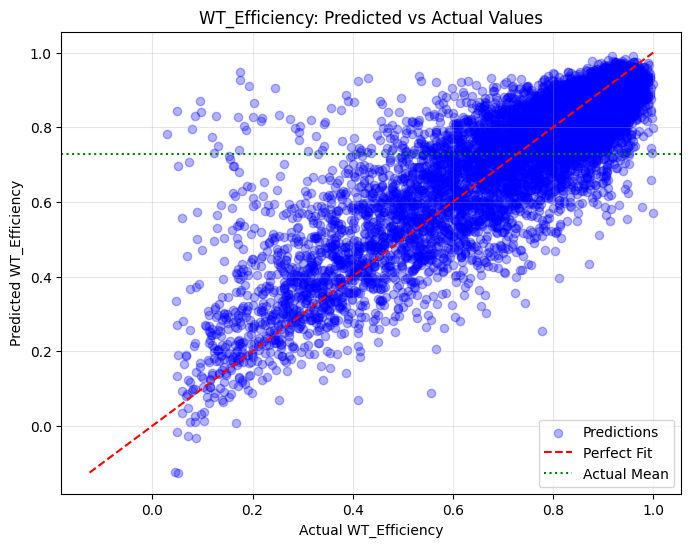

Actual Mean: 0.7271 | Actual Std Dev: 0.2176
Predicted Mean: 0.7295 | Predicted Std Dev: 0.1919

Final Test Performance | R²:  0.7311 | MSE: 0.0127 | MAE: 0.0789


In [ ]:
# 1. Generate predictions on the test set using correct tokenized/padded data
y_pred = best_model.predict(X_test_padded).flatten()

# 2. Plot Predicted vs Actual Values
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Predictions')

# Plot the ideal perfect prediction line (y = x)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', label='Perfect Fit')

# Plot the average line of the actual dataset
plt.axhline(y_test.mean(), color='green', linestyle=':', label='Actual Mean')

plt.title('WT_Efficiency: Predicted vs Actual Values')
plt.xlabel('Actual WT_Efficiency')
plt.ylabel('Predicted WT_Efficiency')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Print summary statistics to numerical compare spread
print(f"Actual Mean: {y_test.mean():.4f} | Actual Std Dev: {y_test.std():.4f}")
print(f"Predicted Mean: {y_pred.mean():.4f} | Predicted Std Dev: {y_pred.std():.4f}")
print(f"\nFinal Test Performance | R²:  {test_r2:.4f} | MSE: {test_mse:.4f} | MAE: {test_mae:.4f}")

# Grid Search Conclusion:
* Best Hyperparameters: `embedding_dim`: 64, `lstm_units`: 128, `learning_rate`:0.0005, `batch_size`: 128, `epochs`:20
* Final Test Performance: `R^2`: 0.7311, `MSE`: 0.0127, `MAE`: 0.0789

# 8. Randomized Search for BiLSTM
This implements a randomized hyperparameter search loop tailored for the BiLSTM architecture, similar to the Grid Search setup but sampling random combinations for faster exploration.

In [ ]:
import random
from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd
import tensorflow as tf

# Define the hyperparameter distributions
param_dist_bilstm = {
    'embedding_dim': [32, 64, 128],
    'lstm_units': [64, 128, 256],
    'learning_rate': [0.0001, 0.0005, 0.001, 0.002],
    'batch_size': [64, 128, 256],
    'epochs': [10, 15, 20]
}

# Helper to sample a random combination
def sample_hyperparameters(param_dist):
    return {
        'embedding_dim': random.choice(param_dist['embedding_dim']),
        'lstm_units': random.choice(param_dist['lstm_units']),
        'learning_rate': random.choice(param_dist['learning_rate']),
        'batch_size': random.choice(param_dist['batch_size']),
        'epochs': random.choice(param_dist['epochs'])
    }

# Number of random combinations to try
n_iter_search = 8
random_search_results = []
visited_combinations = set()

best_val_r2_rs = float('-inf')
best_params_rs = None

print(f"Starting Randomized Search (trying {n_iter_search} unique combinations)...\n")

# Set random seeds for reproducibility
random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

for i in range(n_iter_search):
    # Sample a unique combination
    while True:
        params = sample_hyperparameters(param_dist_bilstm)
        param_tuple = tuple(params.items())
        if param_tuple not in visited_combinations:
            visited_combinations.add(param_tuple)
            break

    print(f"Iteration {i+1}/{n_iter_search}: {params}")

    # Clear previous graph
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    # Build model using the sample's parameters
    model_rs = Sequential([
        Embedding(input_dim=5, output_dim=params['embedding_dim']),
        Bidirectional(LSTM(params['lstm_units']), merge_mode='sum'),
        Dense(16, activation='elu'),
        Dense(16, activation='elu'),
        Dense(1, activation='linear')
    ])

    model_rs.compile(
        optimizer=Adam(learning_rate=params['learning_rate']),
        loss='mse',
        metrics=['mae', 'R2Score']
    )

    early_stop_rs = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    # Train
    history = model_rs.fit(
        X_train_padded,
        y_train,
        validation_data=(X_val_padded, y_val),
        epochs=params['epochs'],
        batch_size=params['batch_size'],
        callbacks=[early_stop_rs],
        verbose=0
    )

    # Evaluate
    val_mse_rs, val_mae_rs, val_r2_rs = model_rs.evaluate(
        X_val_padded,
        y_val,
        verbose=0
    )

    # Log
    random_search_results.append({
        **params,
        'val_r2': val_r2_rs,
        'val_mse': val_mse_rs,
        'val_mae': val_mae_rs
    })

    print(f"Result -> R²: {val_r2_rs:.4f} | MSE: {val_mse_rs:.4f} | MAE: {val_mae_rs:.4f}\n")

    if val_r2_rs > best_val_r2_rs:
        best_val_r2_rs = val_r2_rs
        best_params_rs = params

print("Random Search Completed!")
print("Best Parameters:", best_params_rs)
print(f"Best Validation R²: {best_val_r2_rs:.4f}")

Starting Randomized Search (trying 8 unique combinations)...

Iteration 1/8: {'embedding_dim': 128, 'lstm_units': 64, 'learning_rate': 0.0001, 'batch_size': 256, 'epochs': 15}
Result -> R²: 0.5285 | MSE: 0.0221 | MAE: 0.1125

Iteration 2/8: {'embedding_dim': 128, 'lstm_units': 64, 'learning_rate': 0.002, 'batch_size': 64, 'epochs': 10}
Result -> R²: 0.7153 | MSE: 0.0133 | MAE: 0.0865

Iteration 3/8: {'embedding_dim': 32, 'lstm_units': 64, 'learning_rate': 0.0005, 'batch_size': 256, 'epochs': 20}
Result -> R²: 0.6832 | MSE: 0.0148 | MAE: 0.0910

Iteration 4/8: {'embedding_dim': 32, 'lstm_units': 256, 'learning_rate': 0.0005, 'batch_size': 256, 'epochs': 20}
Result -> R²: 0.7183 | MSE: 0.0132 | MAE: 0.0847

Iteration 5/8: {'embedding_dim': 128, 'lstm_units': 256, 'learning_rate': 0.002, 'batch_size': 64, 'epochs': 15}
Result -> R²: 0.7173 | MSE: 0.0132 | MAE: 0.0838

Iteration 6/8: {'embedding_dim': 128, 'lstm_units': 128, 'learning_rate': 0.0001, 'batch_size': 64, 'epochs': 20}
Result -

In [ ]:
# Sort and inspect top configurations from Randomized Search
rs_df = pd.DataFrame(random_search_results)
display(rs_df.sort_values(by='val_r2', ascending=False))

,embedding_dim,lstm_units,learning_rate,batch_size,epochs,val_r2,val_mse,val_mae
6,64,128,0.0010,64,10,0.720778,0.013088,0.084053
3,32,256,0.0005,256,20,0.718274,0.013205,0.084728
4,128,256,0.0020,64,15,0.717332,0.013250,0.083750
1,128,64,0.0020,64,10,0.715316,0.013344,0.086526
5,128,128,0.0001,64,20,0.685861,0.014725,0.087701
2,32,64,0.0005,256,20,0.683239,0.014848,0.090963
0,128,64,0.0001,256,15,0.528542,0.022099,0.112452
7,64,64,0.0001,128,10,0.515278,0.022720,0.113949


In [ ]:
# Clear previous model
tf.keras.backend.clear_session()

# Reset seed for reproducibility
tf.keras.utils.set_random_seed(SEED)

# Build best model
best_model = build_model(
    best_params_rs['embedding_dim'],
    best_params_rs['lstm_units'],
    best_params_rs['learning_rate']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train best model
history = best_model.fit(
    X_train_padded,
    y_train,
    validation_data=(X_val_padded, y_val),
    epochs=best_params_rs['epochs'],
    batch_size=best_params_rs['batch_size'],
    callbacks=[early_stop],
    verbose=1
)

# Evaluate on test set
test_mse, test_mae, test_r2 = best_model.evaluate(
    X_test_padded,
    y_test,
    verbose=0
)

print("\nBest Hyperparameters:")

for param, value in best_params_rs.items():
    print(f"{param}: {value}")

print("\nFinal Test Performance:")
print(f"R²:  {test_r2:.4f}")
print(f"MSE: {test_mse:.4f}")
print(f"MAE: {test_mae:.4f}")

Epoch 1/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 58s 80ms/step - R2Score: 0.3257 - loss: 0.0320 - mae: 0.1341 - val_R2Score: 0.5124 - val_loss: 0.0229 - val_mae: 0.1168
Epoch 2/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 80s 78ms/step - R2Score: 0.5675 - loss: 0.0205 - mae: 0.1060 - val_R2Score: 0.6336 - val_loss: 0.0172 - val_mae: 0.0989
Epoch 3/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 49s 74ms/step - R2Score: 0.6454 - loss: 0.0168 - mae: 0.0946 - val_R2Score: 0.6688 - val_loss: 0.0155 - val_mae: 0.0929
Epoch 4/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 49s 74ms/step - R2Score: 0.6761 - loss: 0.0154 - mae: 0.0897 - val_R2Score: 0.6869 - val_loss: 0.0147 - val_mae: 0.0902
Epoch 5/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 82s 74ms/step - R2Score: 0.6950 - loss: 0.0145 - mae: 0.0867 - val_R2Score: 0.7037 - val_loss: 0.0139 - val_mae: 0.0877
Epoch 6/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 51s 76ms/step - R2Score: 0.7099 - loss: 0.0137 - mae: 0.0844 - val_R2Score: 0.7139 - val_loss: 0.0134 - val_mae: 0.0861
Epoch 7/10
665/665 ━━━━━━━━━━━━━━━━━━━━ 

# Random Search Conclusion:
* Best Hyperparameters: `embedding_dim`: 64, `lstm_units`: 128, `learning_rate`:0.001, `batch_size`: 64, `epochs`:10
* Final Test Performance: `R^2`: 0.7100, `MSE`: 0.0137, `MAE`: 0.0849

These conclusions are worse than the grid search conclusions.